In [1]:
import sys,os

sys.path.append(os.path.abspath(os.path.join("..")))

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from src.data import load_csv

In [4]:
df = load_csv('../data/hour.csv')

In [5]:
features = ['atemp', 'hum', 'windspeed']

X = df[features]
y = df['cnt']

In [6]:
from src.models import SimpleLinearRegression, MultipleLinearRegression, GDLinearRegression, SGDLinearRegression

In [7]:
from src.metrics import *

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [9]:
slr_model = SimpleLinearRegression()

mlr_model = MultipleLinearRegression()

gd_mlr = GDLinearRegression()

sgd_mlr = SGDLinearRegression()



C1: From the day 3 model, get predictions and residuals on train and testm

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

In [17]:
model = MultipleLinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

r2_score_train = model.r2_score(X_train, y_train)
print(r2_score_train * 100,"%")

r2_score_test = model.r2_score(X_test, y_test)
print(r2_score_test * 100,"%")


mse_val = np.mean((model.residual(X_train, y_train)) ** 2)
print(mse_val)

mse_val_test = np.mean((model.residual(X_test, y_test)) ** 2)
print(mse_val_test)

27.75778804027268 %
9.631659065685227 %
20135.425315337805
43931.262731775314


As we can see the R2 score dropped from 27.75 to 9.63 as we switch from Train to test.
we have not yet cleaned our dataset, there are collinear, skewed data in our dataset, which is why our model's R2 is less

C2. ★ A metrics function: SSE, SST, R², adjusted R², RMSE, MAE. Pass: train R² is about 0.278 and test R² about 0.096, and on train SSE + the explained part equals SST.

In [12]:
from src.metrics import *

In [21]:
mse_test = mse(y_test, y_pred)
print("MSE TEST: ", mse_test)

rmse = root_mse(y_test, y_pred)
print("RMSE: ", rmse)

mae = mean_absolute_error(y_test, y_pred)
print("MAE: ", mae)

sst = total_sum_of_squares(y_test)
print("SST: ", sst)

sse = sum_of_squared_error(y_test, y_pred)
print("SSE: ", sse)

model_explained_ss = model_sum_of_squares(y_test, y_pred)
print("Model SS: ", model_explained_ss)

y_pred_train = model.predict(X_train)

r2_train = r2_score(y_train, y_pred_train)
print("R2 Train: ", r2_train * 100)

r2_test = r2_score(y_test, y_pred)
print("R2 Test", r2_test * 100)

mse_train = mse(y_train, y_pred_train)
print("MSE TRAIN", mse_train)

adj_r2_train = adjusted_r2score(X_train, y_train, y_pred_train)
print("Adjusted Train R2 Score: ", adj_r2_train * 100)

adj_r2_test = adjusted_r2score(X_test, y_test, y_pred)
print("Adjusted Test R2 Score: ", adj_r2_test*100)


MSE TEST:  43931.262731775314
RMSE:  209.59785955914558
MAE:  147.37020665382337
SST:  168980715.67635214
SSE:  152705069.255651
Model SS:  44575764.44152165
R2 Train:  27.75778804027268
R2 Test 9.631659065685227
MSE TRAIN 20135.425315337805
Adjusted Train R2 Score:  27.742195074168706
Adjusted Test R2 Score:  9.553575821790371


Our defined functions and our class functions match perfectly, let us also check r2 adjusted as well !! 

#### Let us see the residuals of Multiple linear regression..!!

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

#### Residual from .residual() and y_hat from X @ beta

let us use them to plot fitted vs residual pot

C3.★ Residuals against predicted values, with a zero line.

In [10]:
mlr_model.fit(X_train, y_train)

X_plot = mlr_model._add_intercept(X_train)
y_hat = X_plot @ mlr_model.beta_hat


In [11]:
def fit_residual_plot(model, X, y):
    model.fit(X, y)
    X_plot = model._add_intercept(X)
    y_hat = X_plot @ model.beta_hat
    residual = model.residual(X, y)

    plt.figure(figsize=(5,5))
    plt.scatter(y_hat, residual)
    model_name = type(model).__name__
    plt.title(f"{model_name} fitted vs residual scatter-plot")
    plt.axhline(y=0, ls="--", color='red')
    plt.tight_layout()
    plt.show()

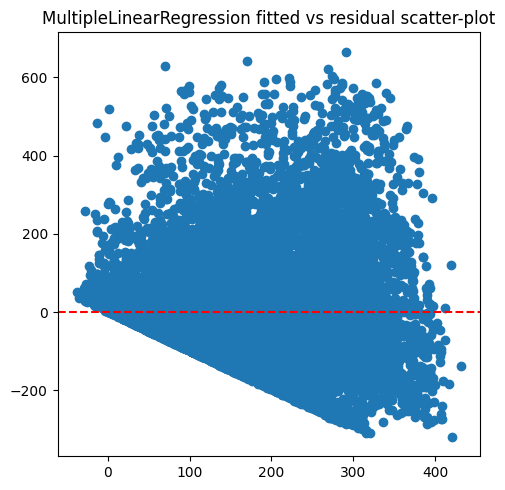

In [12]:
fit_residual_plot(mlr_model, X_train, y_train)

Condition Number: 154.10384248868058
Min Eigen Value:  0.02162819578974133
Learning Rate: 0.3000310762620823 Limit: 0.6000621525241646, Max Eigen value: 3.3329880772966427
Converged at epoch:  344


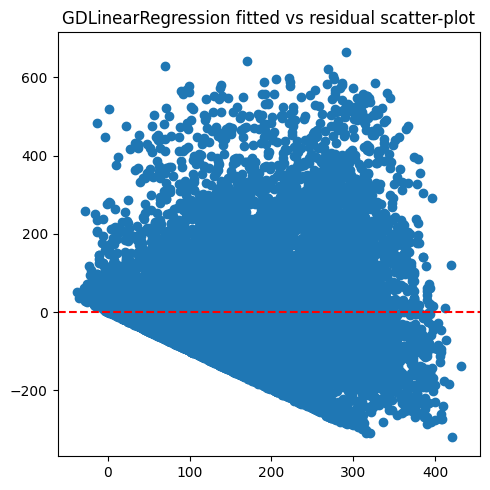

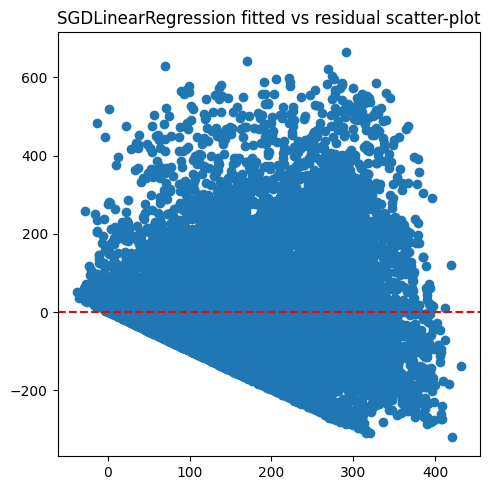

In [13]:
def gd_fit_residual_plot(model, X, y):
    model.fit_gd(X, y)
    X_plot = model._add_intercept(X)
    y_hat = X_plot @ model.beta_hat
    residual = model.residual(X, y)

    plt.figure(figsize=(5,5))
    plt.scatter(y_hat, residual)
    model_name = type(model).__name__
    plt.title(f"{model_name} fitted vs residual scatter-plot")
    plt.axhline(y=0, ls="--", color='red')
    plt.tight_layout()
    plt.show()


gd_fit_residual_plot(gd_mlr, X_train, y_train)


def sgd_fit_residual_plot(model, X, y):
    model.fit_sgd(X, y)
    X_plot = model._add_intercept(X)
    y_hat = X_plot @ model.beta_hat
    residual = model.residual(X, y)

    plt.figure(figsize=(5,5))
    plt.scatter(y_hat, residual)
    model_name = type(model).__name__
    plt.title(f"{model_name} fitted vs residual scatter-plot")
    plt.axhline(y=0, ls="--", color='red')
    plt.tight_layout()
    plt.show()

sgd_fit_residual_plot(sgd_mlr, X_train, y_train)

(13903,) (13903,)


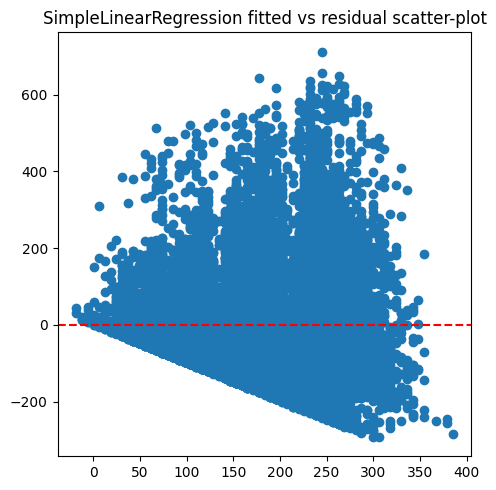

In [14]:
X_slr = df['atemp']
X_tr_slr, X_test_slr, _, _ = train_test_split(X_slr, y, test_size=0.2, shuffle=False)

slr_model.fit(X_tr_slr, y_train)

y_hat = slr_model.beta_0 + (slr_model.beta_1 * (X_tr_slr))

residual = slr_model.residual(X_tr_slr, y_train)

print(y_hat.shape, residual.shape)

plt.figure(figsize=(5,5))
plt.scatter(y_hat, residual)
model_name = type(slr_model).__name__
plt.title(f"{model_name} fitted vs residual scatter-plot")
plt.axhline(y=0, ls="--", color='red')
plt.tight_layout()
plt.show()


for tomorrow's analysis
we need to make the following function in our respective classes:
1. MSE
2. MAE
3. RMSE
4. SST
5. SSR
6. SSE
7. R2
8. ADJUSTED R2
9. BIAS
10. VARIANCE


I realise dwe do not need differet classes, as we have a diagnostics.py in our src section, we can implement fucntions here and rhen store them there and then call it everytime we need something, so let us define the function

C4. Q-Q plot: sort the residuals and plot them against bell-curve quantiles. A straight line means bell-shaped. Check it against scipy.stats.probplot.

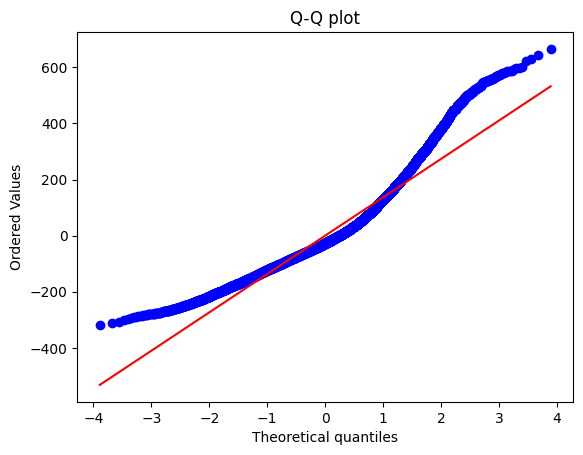

In [ ]:
import scipy.stats as stats

model = MultipleLinearRegression()
model.fit(X_train, y_train)

residual = model.residual(X_train, y_train)

residual_sorted = np.sort(residual)

stats.probplot(residual_sorted, dist='norm', plot=plt)
plt.title("Q-Q plot MLR")
plt.show()


Yoo, doing it for Gradient Descent as well !!

Condition Number: 154.10384248868058
Min Eigen Value:  0.02162819578974133
Learning Rate: 0.3000310762620823 Limit: 0.6000621525241646, Max Eigen value: 3.3329880772966427
Converged at epoch:  344


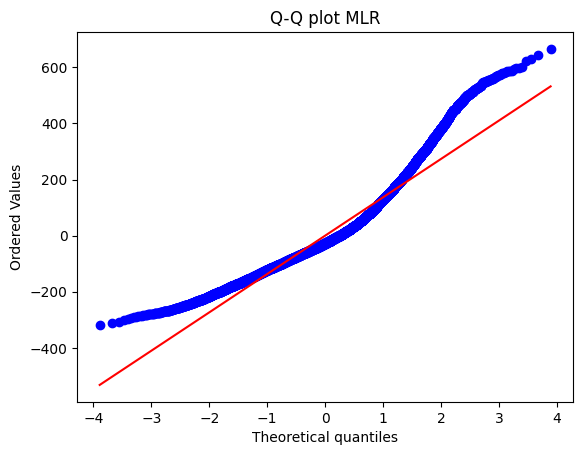

In [26]:
gd_mlr.fit_gd(X_train, y_train)
residual = gd_mlr.residual(X_train, y_train)
residual_sorted = np.sort(residual)

stats.probplot(residual_sorted, dist='norm', plot=plt)
plt.title("Q-Q plot MLR")
plt.show()

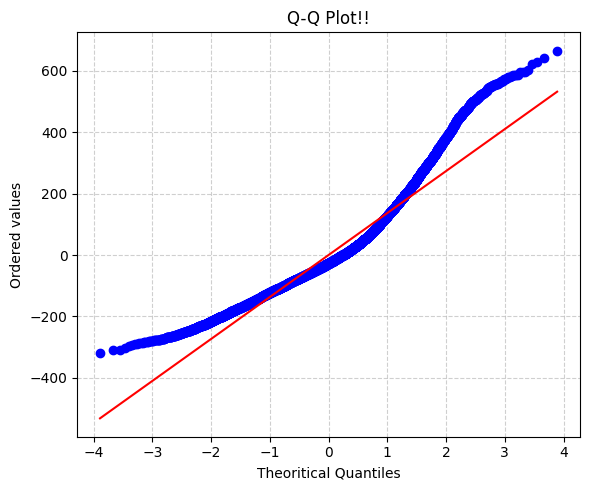

In [27]:
from src.diagnostics import plot_qq

plot_qq(residual=residual, title="Q-Q Plot!!")

C5. ★ Spread plot: the size of the misses against predicted values, with bin averages (pd.qcut and groupby).

In [38]:
model = MultipleLinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
se = (y_test - y_pred) ** 2

spread_df = pd.DataFrame({"prediction": y_pred,"errors":se})

spread_df['pred_bin'] = pd.qcut(spread_df['prediction'], q=10)
bin_summmary = spread_df.groupby('pred_bin', observed=False)['errors'].mean().reset_index()

print(bin_summmary)

bin_midpoints = bin_summmary['pred_bin'].apply(lambda x: x.mid)

                        pred_bin        errors
0  (-22.043000000000003, 66.892]  19485.016475
1               (66.892, 98.288]  29882.866770
2              (98.288, 120.317]  28824.134026
3             (120.317, 138.638]  39884.443867
4             (138.638, 155.607]  34307.600646
5             (155.607, 176.957]  39859.448320
6             (176.957, 201.427]  49848.994582
7             (201.427, 231.285]  47435.750874
8             (231.285, 273.973]  74994.602129
9             (273.973, 389.414]  74974.150505


This is your spread plot bin summary.The Intervals (pred_bin): Your model's predicted values ($\hat{y}$) have been sorted and split into 10 equal-sized buckets (deciles) using pd.qcut. For example, the first bucket contains the lowest 10% of your predictions (ranging from $-22.04$ to $66.89$), and the last bucket contains the highest 10% (ranging from $273.97$ to $389.41$).The Values (errors): The average squared error (or error magnitude) for the data points residing inside that specific prediction bucket.

Low Predictions ($[-22.04, 66.89]$): Average error is ~19,485.Medium Predictions ($[176.95, 201.42]$): Average error climbs to ~49,848.High Predictions ($[273.97, 389.41]$): Average error spikes all the way to ~74,974.

The Big Reveal: Your errors are not constant. As your model makes higher predictions, its misses get drastically larger. This is a textbook mathematical signature of heteroscedasticity (non-constant variance in your errors).

A spread plot with quantile bins tells you where your model is failing:

It checks if your model is only accurate for small values while completely blowing up on large values.

It exposes non-linearities or scaling issues that a simple scatter plot of 13,900 points would hide behind a massive, overlapping visual smudge.

1. Layering the Visual Elements
A great spread plot combines two layers so you don't lose the fine-grained data behind the summary statistics:

The Scatter Layer (Background): Plot your individual predictions on the x-axis and your individual squared/absolute errors on the y-axis. Because you have thousands of points, use a low transparency (alpha) so dense clusters look like a heat map rather than an opaque wall.

The Trend Layer (Foreground): Plot your bin_summary values directly over the scatter points as a bold line with markers (like dots). This gives your eyes an instant, clean path to trace how the average error scales across prediction magnitudes.

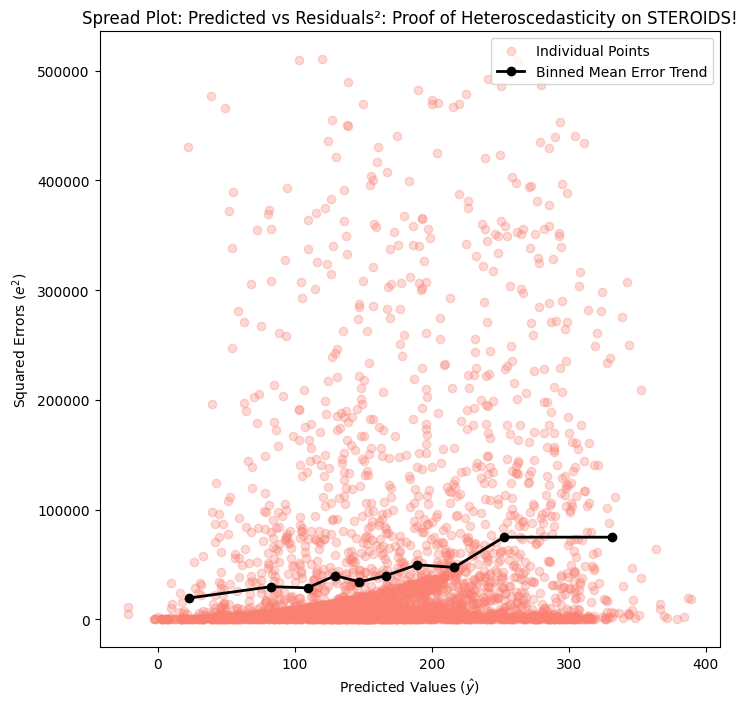

In [40]:
plt.figure(figsize=(8, 8))

# 1. Scatter plot for individual points
plt.scatter(y_pred, se, alpha=0.3, color="salmon", label="Individual Points")

# 2. Line plot with a label for the legend
plt.plot(bin_midpoints,bin_summmary["errors"],marker="o",color="black",linewidth=2, label="Binned Mean Error Trend",)

# 3. Labels and Title
plt.title(
    "Spread Plot: Predicted vs Residuals²: Proof of Heteroscedasticity on"
    " STEROIDS!"
)
plt.xlabel("Predicted Values ($\hat{y}$)")
plt.ylabel("Squared Errors ($e^2$)")

# 4. Activate the legend
plt.legend()

plt.show()

What is "Residuals Against Each Predictor"?This diagnostic step involves creating a separate plot for every single feature in your dataset.Instead of putting your predicted values ($\hat{y}$) on the X-axis like you did in the spread plot, you put one specific feature column ($X_j$) on the X-axis, and your residuals (or squared errors) on the Y-axis.Why Do We Need This? (The Hints)1. Pinpointing Culprits of Non-LinearityIf your overall residual-vs-fitted plot looked curved or messy, this diagnostic lets you look under the hood to see which specific feature is causing the trouble.If a particular feature has a U-shape or a curved pattern when plotted against the residuals, it means that feature has a non-linear relationship with your target, and your linear model is failing to capture it as a straight line.2. Spotting Feature-Specific HeteroscedasticityIt shows you if error variance explodes only when a specific feature gets too large (e.g., errors stay small when feature $X_1$ is low, but blow up when $X_1$ gets high).

In [41]:
X_train

,atemp,hum,windspeed
0,0.2879,0.81,0.0000
1,0.2727,0.80,0.0000
2,0.2727,0.80,0.0000
3,0.2879,0.75,0.0000
4,0.2879,0.75,0.0000
...,...,...,...
13898,0.6667,0.74,0.1343
13899,0.6515,0.70,0.1642
13900,0.6667,0.74,0.1343
13901,0.6970,0.70,0.1343


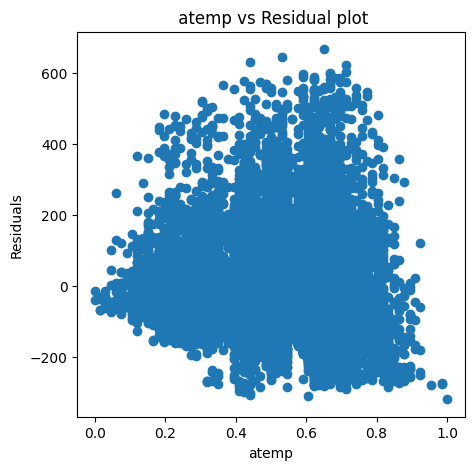

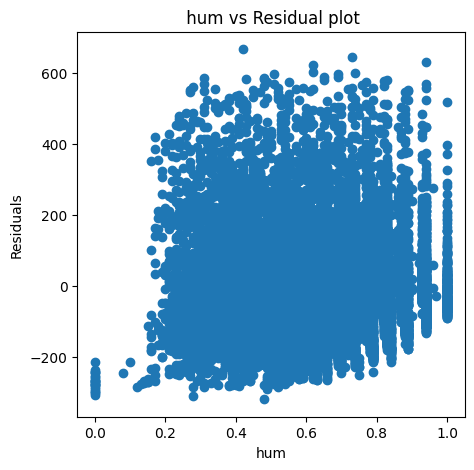

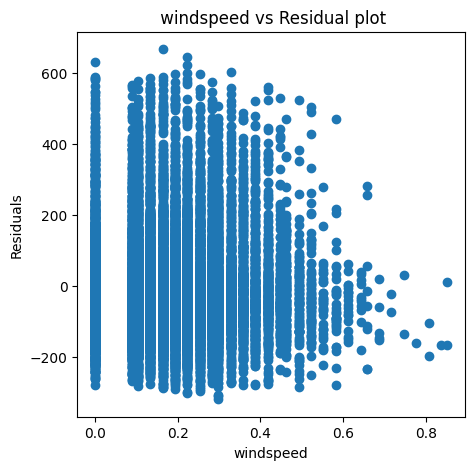

In [43]:
residual = model.residual(X_train, y_train)

for i in range(X_train.shape[1]):
    
    plt.figure(figsize=(5,5))
    plt.scatter(X_train.iloc[:, i], residual)
    plt.title(f" {X_train.columns[i]} vs Residual plot")
    plt.xlabel(f"{X_train.columns[i]}")
    plt.ylabel("Residuals")
    plt.show()

1. atemp vs. Residual PlotWhat you see: The residual cloud is fairly centered around zero, but notice how the vertical spread (the height of the scatter) bulges out in the middle (around $0.4$ to $0.7$) and shrinks near the edges.The Diagnosis: This indicates mild heteroscedasticity tied specifically to temperature extremes. The model's uncertainty grows when feeling temperatures are moderate-to-high, whereas it stays tighter at the absolute extremes.2. hum vs. Residual Plot (Humidity)What you see: Look closely at the left edge (hum = 0.0). The residuals form a flat, truncated horizontal line at the bottom, completely missing positive errors in that zero-humidity bucket. As humidity increases toward $0.4$ and beyond, the spread balloons upward.The Diagnosis: This is a classic signature of a skewed or bounded feature distribution. If humidity has a cluster of zeros or a hard boundary, your linear model struggles to handle the linear boundary condition, causing asymmetric error distribution.3. windspeed vs. Residual PlotWhat you see: This one has a distinct pattern! Look at the vertical column bars caused by discrete or rounded feature values, and notice how the maximum positive errors trend downward as windspeed increases from left to right. At high windspeeds (above $0.6$), the upper boundary of the residuals drops significantly.The Diagnosis: This reveals a non-linear interaction or missing dampening effect. High windspeeds systematically affect the target variable in a way that a straight line cannot capture, leading to biased residuals at higher feature values.

In [ ]:
def _validate_y(y_true):
    y_true = np.asarray(y_true)
    if y_true.size == 0:
        raise ValueError("Input array cannot be empty.")
    if not np.isfinite(y_true).all():
        raise ValueError("Inputs contain NaN or infinite values.")
    return y_true


def _validate_predictions(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    if y_true.size == 0 or y_pred.size == 0:
        raise ValueError("Input arrays cannot be empty.")

    if y_true.shape != y_pred.shape:
        raise ValueError(
            f"Shape mismatch: y_true shape {y_true.shape} must match y_pred shape"
            f" {y_pred.shape}"
        )

    if not np.isfinite(y_true).all() or not np.isfinite(y_pred).all():
        raise ValueError("Inputs contain NaN or infinite values.")

    return y_true, y_pred

def r2_score(y_true, y_pred):
    y_true, y_pred = _validate_predictions(y_true, y_pred)

    sse = np.sum((y_true - y_pred) ** 2)
    sst = np.sum((y_true - np.mean(y_true)) ** 2)

    if np.isclose(sst, 0.0, atol=1e-8):
    # Scikit-learn convention typically returns 0.0 or 1.0 depending on predictions,
    # but returning 0.0 or a safe default is standard.
        return 0.0

    if sst == 0.0:
        return 0
    return 1 - (sse/sst)

def adjusted_r2score(X, y_true, y_pred):
    y_true, y_pred = _validate_predictions(y_true, y_pred)
    
    X = np.asarray(X)
    if X.size == 0:
        raise ValueError("Feature matrix X cannot be empty.")
    if X.shape[0] != y_true.shape[0]:
        raise ValueError(
        f"Sample size mismatch: X has {X.shape[0]} rows, but y_true has"
        f" {y_true.shape[0]} elements.")
    
    

    sse = np.sum((y_true - y_pred) ** 2)
    sst = np.sum((y_true - np.mean(y_true)) ** 2)

    n = y_true.shape[0]

    p = X.shape[1] if len(X.shape) > 1 else 1

    if np.isclose(sst, 0.0, atol=1e-8):
    # Scikit-learn convention typically returns 0.0 or 1.0 depending on predictions,
    # but returning 0.0 or a safe default is standard.
        return 0.0

    if n - p - 1 <=0:
        return 0.0

    adjusted_r2 = 1 - (sse/(n-p-1)) / (sst/ (n - 1))

    return adjusted_r2

def mse(y_true, y_pred):
    y_true, y_pred = _validate_predictions(y_true, y_pred)

    residual = y_true - y_pred
    return np.mean((residual)**2)

def root_mse(y_true, y_pred):
    y_true, y_pred = _validate_predictions(y_true, y_pred)

    residual = y_true - y_pred
    mse = np.mean((residual)**2)
    return np.sqrt(mse)

def mean_absolute_error(y_true, y_pred):
    y_true, y_pred = _validate_predictions(y_true, y_pred)

    abs_error = np.abs(y_true - y_pred)
    return np.mean(abs_error)

def total_sum_of_squares(y_true):
    y_true = _validate_y(y_true)
    return np.sum((y_true - np.mean(y_true)) ** 2)

def model_sum_of_squares(y_true, y_pred):
    y_true, y_pred = _validate_predictions(y_true, y_pred)

    return np.sum((y_pred - np.mean(y_true)) ** 2)

def sum_of_squared_error(y_true, y_pred):
    y_true, y_pred = _validate_predictions(y_true, y_pred)

    return np.sum((y_true - y_pred) ** 2)

_IncompleteInputError: incomplete input (4028966608.py, line 15)